### Import des packages

In [1]:
%%writefile utils.py
import cv2
import os
import numpy as np
img_size = 150
def get_data(path, label):
    data = []
    for img in os.listdir(path):
        try:
            img_arr = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            resized_arr = cv2.resize(img_arr, (img_size, img_size)) # Reshaping images to preferred size
            data.append([resized_arr, label])
        except Exception as e:
            print(e)
    return data


Overwriting utils.py


In [2]:
# Importer les packages
import matplotlib.pyplot as plt
import seaborn as sns
import keras
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D , MaxPool2D , Flatten , Dropout , BatchNormalization
from tensorflow.keras.applications import VGG16,DenseNet121
from utils import get_data # Assurez-vous d'avoir le fichier utils.py dans content

### Import des données

In [ ]:
# Installer le drive
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# Installer kaggle
#!pip install kaggle

In [ ]:
# Définir kaggle configuration
#import os
#os.environ['KAGGLE_CONFIG_DIR'] = '/content/drive/MyDrive/kaggle'
# Mettre le fichier kaggle.json dans le dossier kaggle

In [ ]:
# Télécharger les données
#!kaggle datasets download -d tawsifurrahman/tuberculosis-tb-chest-xray-dataset

In [ ]:
# Déziper le fichier des données
#!unzip /content/tuberculosis-tb-chest-xray-dataset.zip

In [ ]:
import os
print(os.listdir('/kaggle/input'))

In [ ]:
import os
for dirname, subdirs, filenames in os.walk('/kaggle/input'):
    print(dirname)
    if 'Normal' in subdirs and 'Tuberculosis' in subdirs:
        print(">>> TROUVÉ :", dirname)
        break

In [4]:
# Récupérer les données images converties en matrice et labelisées en utilisant la fonction get_data
base = '/kaggle/input/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset/TB_Chest_Radiography_Database'

Normal = get_data(f'{base}/Normal', 0)
Tuberculosis = get_data(f'{base}/Tuberculosis', 1)

In [24]:
import numpy as np
from sklearn.model_selection import train_test_split

data = Normal + Tuberculosis
X = np.array([d[0] for d in data], dtype='float32') / 255.0
y = np.array([d[1] for d in data])

# si les images sont en niveaux de gris (150,150), on ajoute le canal
if X.ndim == 3:
    X = np.stack([X]*3, axis=-1)

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

(2940, 150, 150, 3) (630, 150, 150, 3) (630, 150, 150, 3)


In [25]:
# Afficher l'image en matrice de la première image normal et son label
Normal[1]

[array([[233, 223, 213, ..., 225, 227, 239],
        [210, 192, 167, ..., 204, 212, 223],
        [169,  73,  25, ..., 177, 186, 198],
        ...,
        [ 17,  17,  17, ...,  12,  23,  94],
        [ 17,  17,  17, ...,  12,  23,  98],
        [ 17,  17,  17, ...,  12,  24, 102]], dtype=uint8),
 0]

In [26]:
# Afficher l'image en matrice de la deuxieme image Tuberculosis et son label
Tuberculosis[2]

[array([[208, 208, 208, ..., 208, 209, 209],
        [218, 218, 218, ..., 218, 218, 217],
        [216, 217, 219, ..., 215, 214, 215],
        ...,
        [210, 181, 112, ...,  81,  77, 206],
        [210, 181, 107, ...,  81,  78, 208],
        [209, 203, 135, ..., 103, 105, 219]], dtype=uint8),
 1]

### Exploration et preparation des données

In [27]:
# Images normal et labels
normal_images = [image[0] for image in Normal]
normal_labels = [label[1] for label in Normal]
# Images tuberculosis et labels
tuberculosis_images = [image[0] for image in Tuberculosis]
tuberculosis_labels = [label[1] for label in Tuberculosis]

In [29]:
# Matrice des images
data_images = np.array(normal_images + tuberculosis_images)
# Labels des images
data_labels = np.array(normal_labels + tuberculosis_labels)

In [30]:
# Afficher la dimension
data_images.shape

(4200, 150, 150)

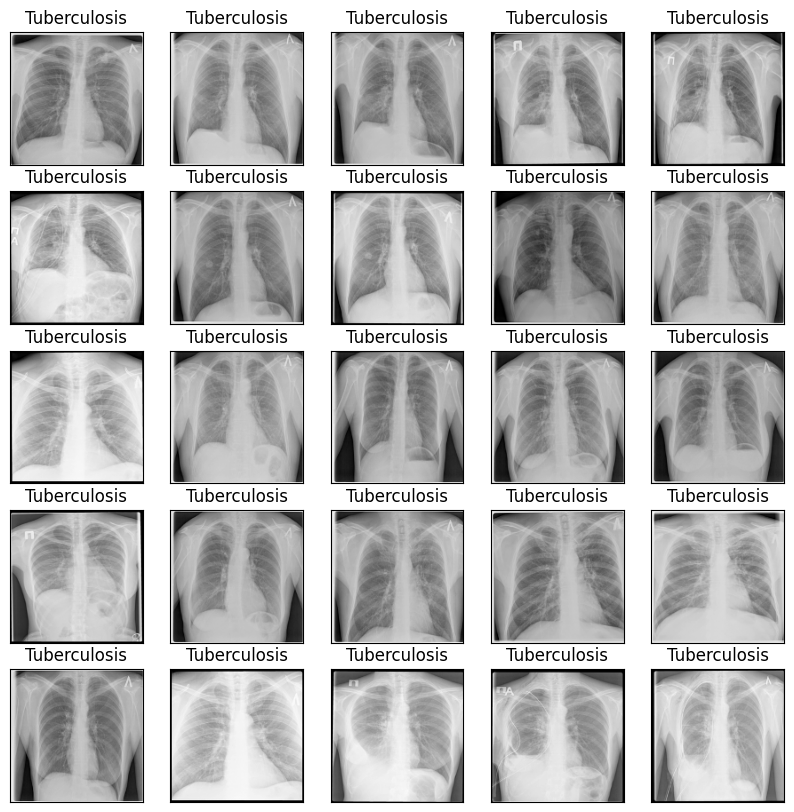

In [31]:
# Visualiser les 25 premières images des données
labels_str = ['Normal', 'Tuberculosis']
plt.figure(figsize=(10,10))
for i in range(25):
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(data_images[data_images.shape[0] - i - 1], cmap = 'gray')
  plt.title(labels_str[data_labels[data_images.shape[0] - i - 1]])

In [32]:
# Nombre d'images  dans chaque classe
pd.Series(data_labels).value_counts()

0    3500
1     700
Name: count, dtype: int64

<Axes: >

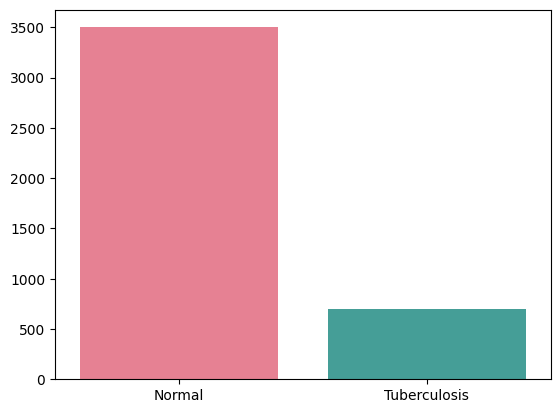

In [33]:
# Barplot du nombre d'images dans chaque classe
labels = ['Normal', 'Tuberculosis']
labels_numb = pd.Series(data_labels).value_counts().values
sns.barplot(x = labels, y =labels_numb, hue =labels,  palette= sns.husl_palette(2))

In [34]:
# spliter les données
from sklearn.model_selection import train_test_split
train_images,test_images, train_labels,test_labels = train_test_split(data_images, data_labels, test_size= 0.2, random_state=42)

In [35]:
# Normaliser
train_images,test_images = train_images/255, test_images/255

In [36]:
# Ajouter la dimension des canaux : (N, 150, 150) -> (N, 150, 150, 1)
train_images = np.expand_dims(train_images, axis=-1)
test_images = np.expand_dims(test_images, axis=-1)

In [37]:
# Répéter le canal gris 3 fois : (N, 150, 150, 1) -> (N, 150, 150, 3)
train_images = np.repeat(train_images, 3, axis=-1)
test_images = np.repeat(test_images, 3, axis=-1)

In [38]:
!pip install -q keras-tuner
import keras_tuner as kt

In [39]:
def build_model(hp):
    model = Sequential()
    for i in range(4):
        filters = hp.Choice(f'filters_{i+1}', [8, 16, 32, 64, 128])
        if i == 0:
            model.add(Conv2D(filters, (3, 3), activation='relu', padding='same', input_shape=(150,150,3)))
        else:
            model.add(Conv2D(filters, (3, 3), activation='relu', padding='same'))
        model.add(MaxPool2D((2, 2)))
    model.add(Flatten())
    model.add(Dense(hp.Choice('units_1', [16, 32, 64, 128, 256]), activation='relu'))
    model.add(Dense(hp.Choice('units_2', [8, 16, 32, 64, 128]), activation='relu'))
    model.add(Dense(hp.Choice('units_3', [8, 16, 32, 64]), activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

Ces cellules utilisent X_train, y_train, X_val, y_val. Si dans ton notebook les variables s'appellent autrement (par exemple x_train, x_test), remplace-les par les tiennes dans la cellule C.

Après, tu remplaces les chiffres dans ta cellule modèle par les 7 valeurs affichées.

lancer la recherche

In [40]:
tuner = kt.Hyperband(
    build_model,
    objective='val_accuracy',
    max_epochs=15,
    factor=3,
    directory='/kaggle/working/tuner',
    project_name='tb_cnn',
    overwrite=True
)

tuner.search(X_train, y_train, validation_data=(X_val, y_val), epochs=15, batch_size=32)

best_hp = tuner.get_best_hyperparameters(1)[0]
for k in ['filters_1','filters_2','filters_3','filters_4','units_1','units_2','units_3']:
    print(k, ":", best_hp.get(k))

Trial 30 Complete [00h 00m 59s]
val_accuracy: 0.9873015880584717

Best val_accuracy So Far: 0.9936507940292358
Total elapsed time: 00h 16m 05s
filters_1 : 32
filters_2 : 64
filters_3 : 128
filters_4 : 128
units_1 : 256
units_2 : 8
units_3 : 32


### Modèle de base

In [41]:
# Architecture du modèle
model = Sequential()
# Couche convolutive 1 avec 32 filtres
model.add(Conv2D(32, (3, 3), activation='relu',
                 padding='same', input_shape=(150, 150, 3)))
model.add(MaxPool2D((2, 2)))

# Couche convolutive 2 avec 64 filtres
model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
model.add(MaxPool2D((2, 2)))
# Couche convolutive 3 avec 128 filtres
model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
model.add(MaxPool2D((2, 2)))
# Couche convolutive 4 avec 128 filtres
model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
model.add(MaxPool2D((2, 2)))
# Couches Fully Connected
model.add(Flatten())
model.add(Dense(units=256, activation='relu'))  # Dense 1
model.add(Dense(units=8, activation='relu'))    # Dense 2
model.add(Dense(units=32, activation='relu'))   # Dense 3
# Couche de sortie
model.add(Dense(units=1, activation='sigmoid'))

In [42]:
# summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 18, 18, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     2,654,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │         2,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,897,673 (11.05 MB)

 Trainable params: 2,897,673 (11.05 MB)

 Non-trainable params: 0 (0.00 B)

In [43]:
from keras.callbacks import EarlyStopping
# Compiler le modèle
model.compile(optimizer = 'adam', loss='binary_crossentropy', metrics=['accuracy', 'precision', 'recall'])
# Définir le early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3)
# Entrainer le modèle
history = model.fit(train_images, train_labels, validation_data =(test_images,test_labels), epochs=20,batch_size= 64, callbacks = early_stopping)

Epoch 1/20


E0000 00:00:1795535403.675541     306 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


53/53 ━━━━━━━━━━━━━━━━━━━━ 19s 167ms/step - accuracy: 0.8464 - loss: 0.3400 - precision: 0.7975 - recall: 0.1119 - val_accuracy: 0.8845 - val_loss: 0.2148 - val_precision: 0.8846 - val_recall: 0.3358
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - accuracy: 0.9113 - loss: 0.2144 - precision: 0.8863 - recall: 0.5400 - val_accuracy: 0.9333 - val_loss: 0.1987 - val_precision: 0.8045 - val_recall: 0.7810
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.9515 - loss: 0.1648 - precision: 0.9098 - recall: 0.7886 - val_accuracy: 0.9333 - val_loss: 0.1914 - val_precision: 0.9551 - val_recall: 0.6204
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.9690 - loss: 0.1277 - precision: 0.9338 - recall: 0.8774 - val_accuracy: 0.9690 - val_loss: 0.1181 - val_precision: 0.9111 - val_recall: 0.8978
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.9848 - loss: 0.0949 - precision: 0.9741 - recall: 0.9343 - val_accuracy: 0.9679 - val_loss: 0.1079 - val_pre

### Evaluation

In [44]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# y_pred:  prédictions du modèle sur les données validation
def CM_visualisation(model_objet):
    # Prédictions des deux modèles : probabilité > 0.5 => Tuberculosis (1), sinon Normal (0)
    test_pred = (model_objet.predict(test_images) > 0.5).astype(int).ravel()
    # Confusion matrix
    cnf_matr = confusion_matrix(test_labels,test_pred, labels=[0,1])

    # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                  display_labels=['Normal','Tuberculosis'])
    disp.plot() # Afficher la matrice de confusion
    plt.title('Matrice de confusion') # Définir le titre
    plt.show() # Afficher la figure

27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step


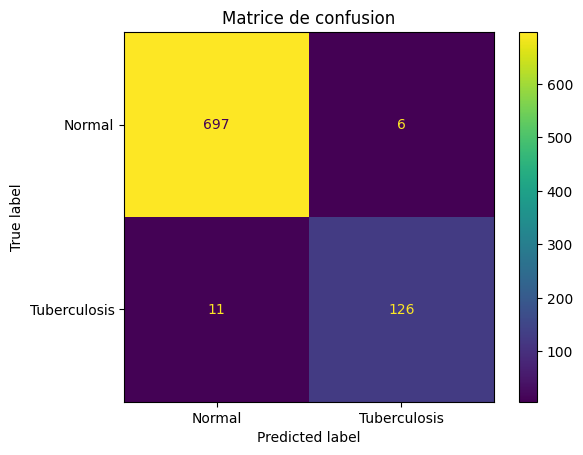

In [45]:
# matrice de confusion
CM_visualisation(model)

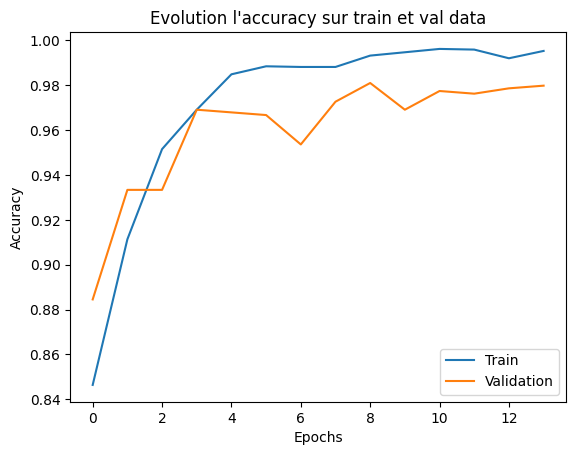

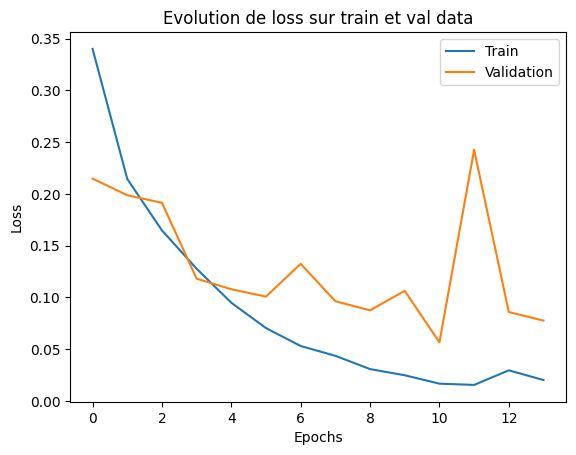

In [46]:
# Afficher l'évolution de l'accuracy sur les données d'entrainement et sur les données suivant les différents epochs
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Evolution l'accuracy sur train et val data")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc = 'lower right')
plt.show()
# Afficher l'évolution du loss sur les données d'entrainement et sur les données suivant les différents epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Evolution de loss sur train et val data")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc = 'upper right')
plt.show()

In [47]:
# Accuracy,loss,precision et recall sur validation data
base_model_metrics = model.evaluate(test_images,test_labels)
print(f'Loss : {base_model_metrics[0]} --- Accuracy : {base_model_metrics[1]} ---Precision: {base_model_metrics[2]}--Recall : {base_model_metrics[3]}')

27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9798 - loss: 0.0776 - precision: 0.9545 - recall: 0.9197
Loss : 0.07762632519006729 --- Accuracy : 0.9797618985176086 ---Precision: 0.9545454382896423--Recall : 0.9197080135345459


In [48]:
# Accuracy et loss sur les données train data
base_model_metrics_train = model.evaluate(train_images,train_labels)
print(f'Loss : {base_model_metrics_train[0]} --- Accuracy : {base_model_metrics_train[1]} ---Precision: {base_model_metrics_train[2]}--Recall : {base_model_metrics_train[3]}')

105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9985 - loss: 0.0080 - precision: 0.9982 - recall: 0.9929
Loss : 0.008030337281525135 --- Accuracy : 0.9985119104385376 ---Precision: 0.9982143044471741--Recall : 0.9928951859474182


## la fonction avec les hyperparamètres

In [50]:
from tensorflow.keras.optimizers import Adam

def build_vgg(hp):
    base = VGG16(weights='imagenet', include_top=False, input_shape=(150, 150, 3))
    base.trainable = False

    model = Sequential()
    model.add(base)
    model.add(Flatten())

    # Fully connected : neurones
    model.add(Dense(hp.Choice('units_1', [128, 256, 512, 1024]), activation='relu'))
    # Dropout 1
    model.add(Dropout(hp.Choice('dropout_1', [0.2, 0.3, 0.4, 0.5, 0.6])))
    model.add(Dense(hp.Choice('units_2', [64, 128, 256, 512]), activation='relu'))
    # Dropout 2
    model.add(Dropout(hp.Choice('dropout_2', [0.2, 0.3, 0.4, 0.5])))
    model.add(Dense(1, activation='sigmoid'))

    # Learning rate
    lr = hp.Choice('learning_rate', [1e-2, 1e-3, 1e-4])
    model.compile(optimizer=Adam(learning_rate=lr), loss='binary_crossentropy', metrics=['accuracy'])
    return model

In [69]:
import os

print(os.listdir(f'{base}/Tuberculosis')[:10])

['Tuberculosis-1.png', 'Tuberculosis-10.png', 'Tuberculosis-100.png', 'Tuberculosis-101.png', 'Tuberculosis-102.png', 'Tuberculosis-103.png', 'Tuberculosis-104.png', 'Tuberculosis-105.png', 'Tuberculosis-106.png', 'Tuberculosis-107.png']


### lancer la recherche

In [51]:
tuner_vgg = kt.Hyperband(
    build_vgg,
    objective='val_accuracy',
    max_epochs=10,
    factor=3,
    directory='/kaggle/working/tuner',
    project_name='tb_vgg16',
    overwrite=True
)

tuner_vgg.search(X_train, y_train, validation_data=(X_val, y_val), epochs=10, batch_size=32)

best_vgg = tuner_vgg.get_best_hyperparameters(1)[0]
for k in ['units_1', 'dropout_1', 'units_2', 'dropout_2', 'learning_rate']:
    print(k, ":", best_vgg.get(k))

Trial 30 Complete [00h 01m 37s]
val_accuracy: 0.8333333134651184

Best val_accuracy So Far: 0.9920634627342224
Total elapsed time: 00h 23m 02s
units_1 : 1024
dropout_1 : 0.3
units_2 : 512
dropout_2 : 0.4
learning_rate : 0.0001


ta cellule VGG16, avec tes valeurs

Tu gardes ta cellule et tu changes seulement ces 4 chiffres              
vgg16_model.add(Dense(units=U1, activation='relu'))   # U1 = units_1
vgg16_model.add(Dropout(D1))                          # D1 = dropout_1
vgg16_model.add(Dense(units=U2, activation='relu'))   # U2 = units_2
vgg16_model.add(Dropout(D2))                          # D2 = dropout_2

### Modèle VGG16

In [52]:
# Charger VGG16 préentrainé sans les couches de classification (Sans couches fully connected)
base_vgg16 = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(150, 150, 3)
)

# Geler les couches de base (Leurs poids, appris sur ImageNet, restent fixes pendant l’entraînement)
base_vgg16.trainable = False
# Construire le modèle VGG16 avec Sequential
vgg16_model = Sequential()
# Ajouter le modèle de base VGG16
vgg16_model.add(base_vgg16) # ajouter les couches de convolutions du modèle vgg16
# Applanir
vgg16_model.add(Flatten())
# Couches fully connected ---------------------------------------------
# Couche Dense 1 avec 1024 neurones
vgg16_model.add(Dense(units=1024, activation='relu'))
# Couche Dropout 1
vgg16_model.add(Dropout(0.3))
# Couche Dense 2 avec 512 neurones
vgg16_model.add(Dense(units=512, activation='relu'))
# Couche Dropout 2
vgg16_model.add(Dropout(0.4))
# Couche de sortie pour classification binaire
vgg16_model.add(Dense(units=1, activation='sigmoid'))

In [53]:
# summary
vgg16_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1024)           │     8,389,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,629,633 (90.14 MB)

 Trainable params: 8,914,945 (34.01 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [54]:
from keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=3)
# Compiler VGG16 customisé
vgg16_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', 'precision', 'recall']
)
# Entraînement VGG16
history_vgg16 = vgg16_model.fit(train_images, train_labels, validation_data= (test_images, test_labels), epochs = 20,batch_size = 64, callbacks=early_stopping)

Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 23s 306ms/step - accuracy: 0.8970 - loss: 0.3102 - precision: 0.7219 - recall: 0.6270 - val_accuracy: 0.9738 - val_loss: 0.0724 - val_precision: 0.8966 - val_recall: 0.9489
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 192ms/step - accuracy: 0.9792 - loss: 0.0625 - precision: 0.9506 - recall: 0.9236 - val_accuracy: 0.9893 - val_loss: 0.0418 - val_precision: 0.9638 - val_recall: 0.9708
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 186ms/step - accuracy: 0.9851 - loss: 0.0418 - precision: 0.9672 - recall: 0.9432 - val_accuracy: 0.9905 - val_loss: 0.0343 - val_precision: 0.9708 - val_recall: 0.9708
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 181ms/step - accuracy: 0.9848 - loss: 0.0424 - precision: 0.9655 - recall: 0.9432 - val_accuracy: 0.9929 - val_loss: 0.0349 - val_precision: 1.0000 - val_recall: 0.9562
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 9s 179ms/step - accuracy: 0.9914 - loss: 0.0278 - precision: 0.9785 - recall: 0.9698 - val_accuracy: 0.9881 - val_loss

#### Evaluation

27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 100ms/step


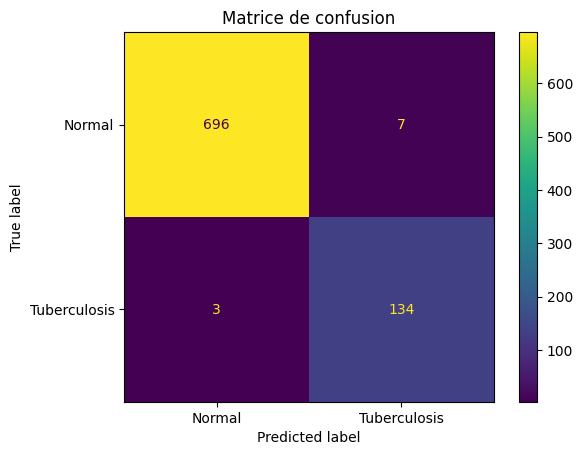

In [55]:
# matrice de confusion
CM_visualisation(vgg16_model)

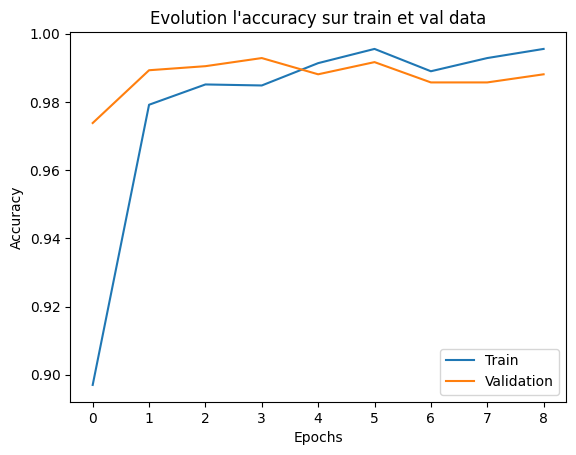

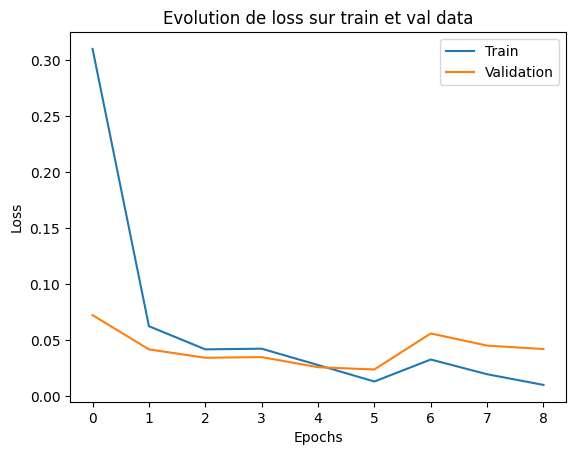

In [56]:
# Afficher l'évolution de l'accuracy sur les données d'entrainement et sur les données validation suivant les différents epochs
plt.plot(history_vgg16.history['accuracy'])
plt.plot(history_vgg16.history['val_accuracy'])
plt.title("Evolution l'accuracy sur train et val data")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc = 'lower right')
plt.show()
# Afficher l'évolution du loss sur les données d'entrainement et sur les données validation suivant les différents epochs
plt.plot(history_vgg16.history['loss'])
plt.plot(history_vgg16.history['val_loss'])
plt.title("Evolution de loss sur train et val data")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc = 'upper right')
plt.show()

In [57]:
# Accuracy,loss,precision et recall sur validation data
vgg16_model_metrics = vgg16_model.evaluate(test_images,test_labels)
print(f'Loss : {vgg16_model_metrics[0]} --- Accuracy : {vgg16_model_metrics[1]} ---Precision: {vgg16_model_metrics[2]}--Recall : {vgg16_model_metrics[3]}')

27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step - accuracy: 0.9881 - loss: 0.0421 - precision: 0.9504 - recall: 0.9781
Loss : 0.042100388556718826 --- Accuracy : 0.988095223903656 ---Precision: 0.9503546357154846--Recall : 0.9781022071838379


In [58]:
# Accuracy et loss sur les données train data
vgg16_model_metrics_train = vgg16_model.evaluate(train_images,train_labels)
print(f'Loss : {vgg16_model_metrics_train[0]} --- Accuracy : {vgg16_model_metrics_train[1]} ---Precision: {vgg16_model_metrics_train[2]}--Recall : {vgg16_model_metrics_train[3]}')

105/105 ━━━━━━━━━━━━━━━━━━━━ 8s 77ms/step - accuracy: 0.9988 - loss: 0.0048 - precision: 0.9947 - recall: 0.9982
Loss : 0.004777582362294197 --- Accuracy : 0.9988095164299011 ---Precision: 0.9946902394294739--Recall : 0.9982237815856934


### Modèle DenseNet121

In [59]:
# Importer DenseNet121
from tensorflow.keras.applications import DenseNet121

In [60]:
# Charger DenseNet121 préentrainé sans les couches de classification (Sans couches fully connected)
base_densenet = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(150, 150, 3)
)

# Geler les couches de base
base_densenet.trainable = False
# Construire le modèle DenseNet121 avec Sequential
densenet_model = Sequential()
# Ajouter le modèle de base DenseNet121
densenet_model.add(base_densenet) # ajouter les couches de convolutions du modèle DenseNet121
# Applanir
densenet_model.add(Flatten())
# Couche Dense 1 avec 512 neurones
densenet_model.add(Dense(units=512, activation='relu'))
# Couche Dropout 1
densenet_model.add(Dropout(0.5))
# Couche Dense 2 avec 256 neurones
densenet_model.add(Dense(units=256, activation='relu'))
# Couche Dropout 2
densenet_model.add(Dropout(0.3))
# Couche de sortie pour classification binaire
densenet_model.add(Dense(units=1, activation='sigmoid'))

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [61]:
# Compiler DenseNet121 customisé
densenet_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', 'precision', 'recall']
)
# Entraînement DenseNet121
history_densenet = densenet_model.fit(train_images, train_labels, validation_data = (test_images,test_labels), epochs = 20,batch_size =64, callbacks=early_stopping)

Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 71s 816ms/step - accuracy: 0.8589 - loss: 1.2370 - precision: 0.5848 - recall: 0.5453 - val_accuracy: 0.9643 - val_loss: 0.1006 - val_precision: 0.8639 - val_recall: 0.9270
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - accuracy: 0.9560 - loss: 0.1584 - precision: 0.8752 - recall: 0.8597 - val_accuracy: 0.9726 - val_loss: 0.0657 - val_precision: 0.8851 - val_recall: 0.9562
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - accuracy: 0.9705 - loss: 0.0804 - precision: 0.9143 - recall: 0.9094 - val_accuracy: 0.9810 - val_loss: 0.0542 - val_precision: 0.9116 - val_recall: 0.9781


#### Evaluation

27/27 ━━━━━━━━━━━━━━━━━━━━ 24s 486ms/step


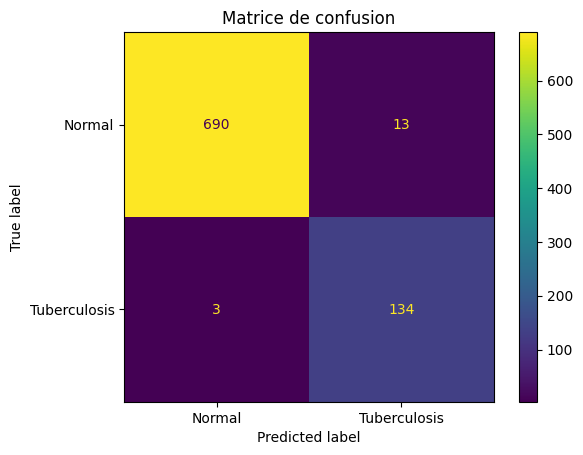

In [62]:
# Matrice de confusion
CM_visualisation(densenet_model)

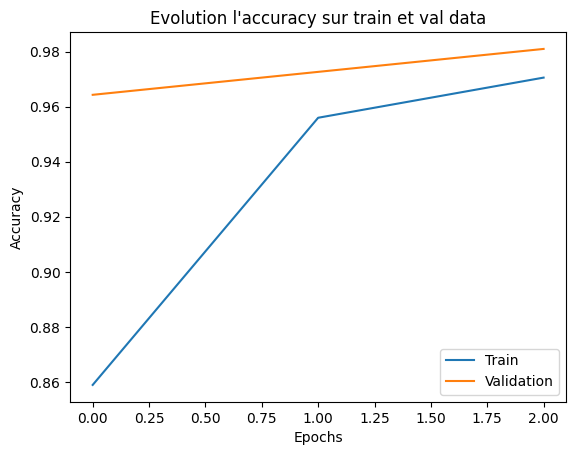

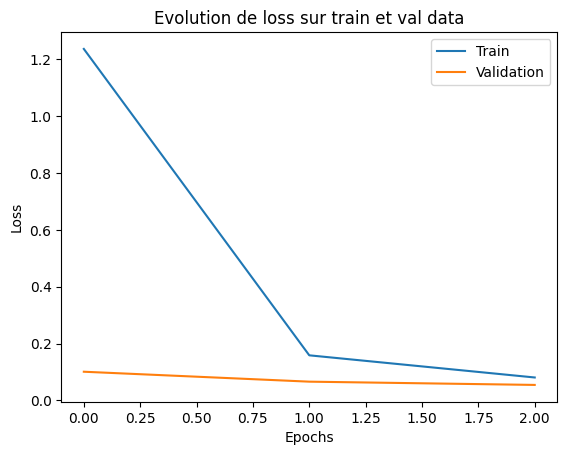

In [63]:
# Afficher l'évolution de l'accuracy sur les données d'entrainement et sur les données validation suivant les différents epochs
plt.plot(history_densenet.history['accuracy'])
plt.plot(history_densenet.history['val_accuracy'])
plt.title("Evolution l'accuracy sur train et val data")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc = 'lower right')
plt.show()
# Afficher l'évolution du loss sur les données d'entrainement et sur les données validation suivant les différents epochs
plt.plot(history_densenet.history['loss'])
plt.plot(history_densenet.history['val_loss'])
plt.title("Evolution de loss sur train et val data")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc = 'upper right')
plt.show()

In [64]:
# Accuracy,loss,precision et recall sur validation data
densenet_model_metrics = densenet_model.evaluate(test_images,test_labels)
print(f'Loss : {densenet_model_metrics[0]} --- Accuracy : {densenet_model_metrics[1]} ---Precision: {densenet_model_metrics[2]}--Recall : {densenet_model_metrics[3]}')

27/27 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - accuracy: 0.9810 - loss: 0.0542 - precision: 0.9116 - recall: 0.9781
Loss : 0.05419405549764633 --- Accuracy : 0.9809523820877075 ---Precision: 0.9115646481513977--Recall : 0.9781022071838379


In [65]:
# Accuracy et loss sur les données train data
densenet_model_metrics_train = densenet_model.evaluate(train_images,train_labels)
print(f'Loss : {densenet_model_metrics_train[0]} --- Accuracy : {densenet_model_metrics_train[1]} ---Precision: {densenet_model_metrics_train[2]}--Recall : {densenet_model_metrics_train[3]}')

105/105 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.9878 - loss: 0.0375 - precision: 0.9516 - recall: 0.9769
Loss : 0.03750155121088028 --- Accuracy : 0.9877976179122925 ---Precision: 0.9515570998191833--Recall : 0.9769093990325928


### Télécharger le modèle le plus performant

In [66]:
# sauvegarde le modèle
vgg16_model.save('vgg16_model_finetuned.h5')
vgg16_model.save('vgg16_model_finetuned.keras')

### Prédictions

In [67]:
# Fonction convertissant l'image à la dimension exacte utilisée sur le training
from PIL import Image

def imageToArray(image_path):

  width, height = 150, 150  #Remplacer par les dimensions requises par notre modèle

  image = Image.open(image_path).convert('RGB')
  image = image.resize((width, height))
  # Convertir l'image en numpy arraay et normaliser les valeurs des pixels (si nécessaire)
  image_array = np.asarray(image)
  image_array = image_array / 255.0  # Normaliser les valeurs des pixels entre 0 et 1

  # Redimensionner la matrice image pour qu'elle correspond à la forme d'entrée de  notre modèle
  image_array = image_array.reshape(-1, width, height, 3)

  return image_array

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


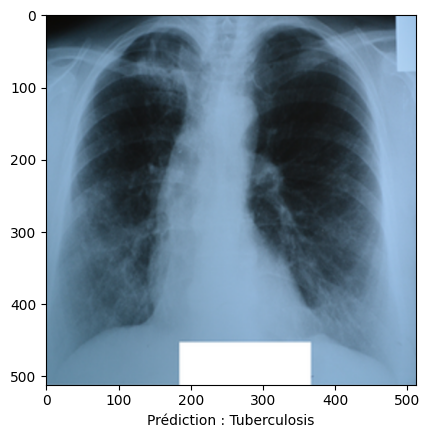

In [70]:
class_names = ['Normal', 'Tuberculosis']
# Predictions
image_path = f'{base}/Tuberculosis/Tuberculosis-1.png'
image = imageToArray(image_path)
pred = int(np.round(vgg16_model.predict(image))[0][0])
pred = class_names[pred]
plt.imshow(Image.open(image_path)) # afficher l'image
plt.xlabel(f'Prédiction : {pred}')
plt.show()

### Deploiement du modèle en utilisant Gradio

In [71]:
import tensorflow as tf
import numpy as np
import gradio as gr
from PIL import Image

# Charger le modèle entraîné
model = tf.keras.models.load_model("vgg16_model_finetuned.h5")  # adapter le nom du fichier

# Paramètres issus de l'entraînement
IMG_SIZE = (150, 150)
CLASSES = ["Normal", "Tuberculosis"]

# Prétraitement + prédiction
def predict(image):
    if image is None:
        return None
    image = image.convert("RGB")                        # gris/RGBA -> 3 canaux
    image = image.resize(IMG_SIZE, Image.NEAREST)       # même interpolation que Keras
    image_array = np.asarray(image, dtype=np.float32) / 255.0  # même rescale
    image_array = np.expand_dims(image_array, axis=0)   # (1, 150, 150, 3)

    p_tb = float(model.predict(image_array, verbose=0)[0][0])
    return {CLASSES[1]: p_tb, CLASSES[0]: 1.0 - p_tb}

# Interface Gradio
interface = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", label="Radiographie thoracique"),
    outputs=gr.Label(num_top_classes=2, label="Résultat"),
    title="Détection de la tuberculose sur radiographie thoracique",
    description=(
        "Téléversez une radiographie thoracique pour estimer la probabilité de tuberculose. "
        "Outil pédagogique : il ne remplace pas un diagnostic médical."
    ),
    theme="JohnSmith9982/small_and_pretty",
)
interface.launch(share=True)

/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


theme_schema%401.0.0.json:   0%|          | 0.00/13.0k [00:00<?, ?B/s]

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://0143b0a4743ef1c468.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [72]:
import os

for root, dirs, files in os.walk('/kaggle/working'):
    for file in files:
        print(os.path.join(root, file))

/kaggle/working/vgg16_model_finetuned.keras
/kaggle/working/vgg16_model_finetuned.h5
/kaggle/working/utils.py
/kaggle/working/tuner/tb_vgg16/tuner0.json
/kaggle/working/tuner/tb_vgg16/oracle.json
/kaggle/working/tuner/tb_vgg16/trial_0025/trial.json
/kaggle/working/tuner/tb_vgg16/trial_0025/build_config.json
/kaggle/working/tuner/tb_vgg16/trial_0025/checkpoint.weights.h5
/kaggle/working/tuner/tb_vgg16/trial_0029/trial.json
/kaggle/working/tuner/tb_vgg16/trial_0029/build_config.json
/kaggle/working/tuner/tb_vgg16/trial_0029/checkpoint.weights.h5
/kaggle/working/tuner/tb_vgg16/trial_0021/trial.json
/kaggle/working/tuner/tb_vgg16/trial_0021/build_config.json
/kaggle/working/tuner/tb_vgg16/trial_0021/checkpoint.weights.h5
/kaggle/working/tuner/tb_vgg16/trial_0001/trial.json
/kaggle/working/tuner/tb_vgg16/trial_0001/build_config.json
/kaggle/working/tuner/tb_vgg16/trial_0001/checkpoint.weights.h5
/kaggle/working/tuner/tb_vgg16/trial_0019/trial.json
/kaggle/working/tuner/tb_vgg16/trial_0019/b